### Resampling Methods 
2026-10-12 Luobin Wang


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import make_pipeline


In [2]:
df = pd.read_csv("pollution_cleaneddata.csv")
print(len(df))
df.head()
df.describe()

60


,PREC,JANT,JULT,OVR65,POPN,EDUC,HOUS,DENS,NONW,WWDRK,POOR,HC,NOX,SO@,HUMID,MORT
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.00000,60.000000,60.000000,60.000000
mean,37.366667,33.983333,74.583333,8.798333,3.263167,10.973333,80.913333,3876.050000,11.870000,46.081667,14.373333,37.850000,22.65000,53.766667,57.666667,940.358433
std,9.984678,10.168899,4.763177,1.464552,0.135252,0.845299,5.141373,1454.102361,8.921148,4.613043,4.160096,91.977673,46.33329,63.390468,5.369931,62.206278
min,10.000000,12.000000,63.000000,5.600000,2.920000,9.000000,66.800000,1441.000000,0.800000,33.800000,9.400000,1.000000,1.00000,1.000000,38.000000,790.733000
25%,32.750000,27.000000,72.000000,7.675000,3.210000,10.400000,78.375000,3104.250000,4.950000,43.250000,12.000000,7.000000,4.00000,11.000000,55.000000,898.372000
50%,38.000000,31.500000,74.000000,9.000000,3.265000,11.050000,81.150000,3567.000000,10.400000,45.500000,13.200000,14.500000,9.00000,30.000000,57.000000,943.683000
75%,43.250000,40.000000,77.250000,9.700000,3.360000,11.500000,83.600000,4519.750000,15.650000,49.525000,15.150000,30.250000,23.75000,69.000000,60.000000,983.205750
max,60.000000,67.000000,85.000000,11.800000,3.530000,12.300000,90.700000,9699.000000,38.500000,59.700000,26.400000,648.000000,319.00000,278.000000,73.000000,1113.156000


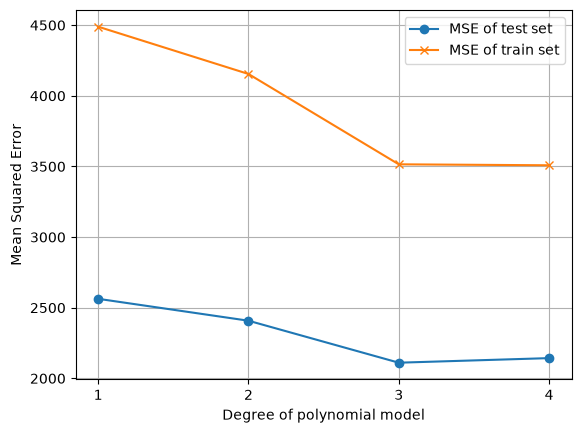

In [3]:
x =df[['JULT']] # transform x to a 2D array, which df['JULT'] is a series
y = df['MORT']

'''stand scale polynomial '''
x_tr, x_te, y_tr, y_te = train_test_split(x,y, test_size = 0.5, random_state=5)
test_mse = []
train_mse = []
degrees = range(1,5)

x_model = pd.DataFrame({'JULT':np.linspace(x['JULT'].min(),x['JULT'].max())})
for d in degrees:
    model = make_pipeline(StandardScaler(),
                                 PolynomialFeatures(degree = d, include_bias=False),
                                 LinearRegression())

    model.fit(x_tr, y_tr)
    y_pred_te = model.predict(x_te)
    y_pred_tr = model.predict(x_tr)
    
    test_mse.append(mean_squared_error(y_te, y_pred_te))
    train_mse.append(mean_squared_error(y_tr, y_pred_tr))


plt.xlabel("Degree of polynomial model")
plt.ylabel("Mean Squared Error")
plt.plot(degrees, test_mse, marker = "o", label = "MSE of test set")
plt.plot(degrees, train_mse, marker = "x", label = "MSE of train set")
plt.xticks([1,2,3,4])

plt.legend()
plt.grid()
plt.show()


Both test and train MSE are decreasing with rising of degree and test set MSE is always smaller than train set. However, lecture note is telling about MSE_test should be large than MSE_train, I supporst it is coincidently due to the seed = 5. Degree = 4 gave the smallest MSE, which is recommended to use to achieve the samllest the variance.

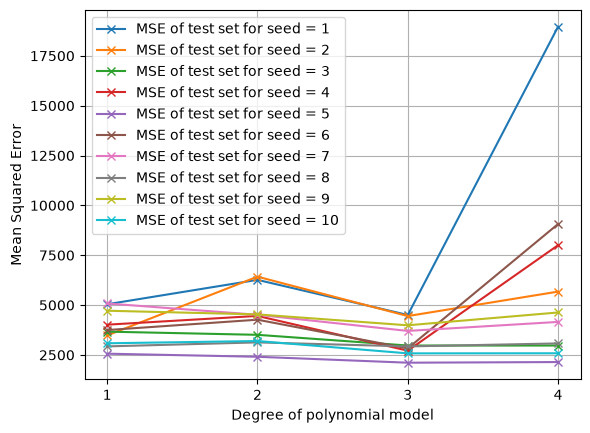

In [4]:
seed = range(1,11)
for s in seed:
    x_tr, x_te, y_tr, y_te = train_test_split(x,y, test_size = 0.5, random_state=s)
    mse = []
    for d in degrees:
        model = make_pipeline(StandardScaler(),
                                 PolynomialFeatures(degree = d, include_bias=False),
                                 LinearRegression())
        model.fit(x_tr,y_tr)
        y_pred_te = model.predict(x_te)
        mse.append(mean_squared_error(y_te, y_pred_te))
    plt.plot(degrees, mse, marker = "x", label = f"MSE of test set for seed = {s}")

plt.xlabel("Degree of polynomial model")
plt.ylabel("Mean Squared Error")

plt.xticks([1,2,3,4])

plt.legend()
plt.grid()
plt.show()

In [5]:
# K-fold cross-validation
kf = KFold(n_splits= 3, shuffle = True, random_state = 5 )

model_k = make_pipeline(StandardScaler(),
                                 PolynomialFeatures(degree = 2, include_bias=False),
                                 LinearRegression())
k_mse = []
for i, (train_index, test_index) in enumerate(kf.split(x)):
    x_train, x_test = x.iloc[train_index], x.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    model_k.fit(x_train, y_train)

    y_pred_k = model_k.predict(x_test)
    k_mse.append(mean_squared_error(y_test, y_pred_k))
    print(f'fold = {i}: MSE = {mean_squared_error(y_test, y_pred_k): 1f}')
print(f"cv MSE = {np.mean(k_mse): 1f}")

fold = 0: MSE =  2111.513515
fold = 1: MSE =  2827.456626
fold = 2: MSE =  6833.629482
cv MSE =  3924.199874


In [6]:
# MSE changes with ten seed values
seed = range(1,11)
#ava_s_mse = []
for d in seed:
    kf = KFold(n_splits= 3, shuffle = True, random_state = d )
    mse_d = []
    for i, (train_index, test_index) in enumerate(kf.split(x)):
            x_train, x_test = x.iloc[train_index], x.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]
            model_k.fit(x_train, y_train)

            y_pred_i = model_k.predict(x_test)

            mse_i = mean_squared_error(y_test, y_pred_i)
            mse_d.append(mse_i)
            #print(f"fold = {i}: MSE = {mse_i: 1f}")
    print(f'seed = {d}, cv MSE = {np.mean(mse_d):1f}')

seed = 1, cv MSE = 5175.994078
seed = 2, cv MSE = 5176.310229
seed = 3, cv MSE = 3513.029877
seed = 4, cv MSE = 3826.803794
seed = 5, cv MSE = 3924.199874
seed = 6, cv MSE = 5740.597705
seed = 7, cv MSE = 3758.749368
seed = 8, cv MSE = 3576.517064
seed = 9, cv MSE = 5723.806750
seed = 10, cv MSE = 3658.313780


For other ten seed values, average MSE changes from 3513 to 5740, that were not similar results. It might be attributed from the small number of Kfold, only 2/3 proportion of data were used to train, and 1/3 for testing. The results might be better if n_split = 5 or 10.